# Climate Comfort Index: DummyRegressor baseline experiment

Student **25945320**. Predicts the Climate Comfort Index at **+1, +2 and +3 days** from the leakage-audited feature
matrix built by the preprocessing notebook.

## Hypothesis

`DummyRegressor` ignores the feature matrix and emits a single constant for every row. That
constant is the loss-minimising prediction when no covariates are used, so this is the correct
null model, and every other CCI experiment must beat it.

The hypothesis under test is narrow but real: **the median will beat the mean on MAE.** The mean
minimises squared error, the median minimises absolute error, and CCI is left-skewed — a long
tail of poor-comfort days pulls the mean below the median. If the two are indistinguishable, the
skew is negligible and MAE and RMSE will rank later models consistently; if the median wins
clearly, the skew is material and the choice of error metric matters more than it appears to.

This notebook is not a deployment candidate. It exists to establish the floor and to confirm that
persistence and climatology — which do use information — sit well below it.

## Design

| Choice | Value | Reason |
|---|---|---|
| Algorithm | `DummyRegressor` | sklearn's canonical regression null model |
| Strategy | One estimator per horizon | Matches the artefact layout of every other CCI notebook |
| Features | Fitted, then ignored | The estimator API still receives `X`, but the constant does not depend on it |
| Scaling | None | A constant prediction is invariant to feature scale |
| Selection | **Exhaustive**, not Optuna | The candidate constants are enumerable, so every one is evaluated and the result is exact rather than best-found |
| Objective | Validation MAE, minimised | The same objective as every other CCI notebook, so the floor is measured on the same scale |

## Notebook structure

All ten experiment notebooks in this project follow the same ten sections and share their
machinery through `modeling.experiment` in the custom package, so results are directly
comparable and a change to a metric or a baseline applies everywhere at once.

| Section | Contents |
|---|---|
| 1 | Load the chronological splits (train and validation only) |
| 2 | Baselines |
| 3 | Model specification and default configuration |
| 4 | Feature-group ablation |
| 5 | Exhaustive selection (no search library) |
| 6 | Final model and evaluation |
| 7 | Feature attribution |
| 8 | Generalisation check |
| 9 | Saved artefacts |
| 10 | Conclusions |

In [1]:
from __future__ import annotations

import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
warnings.filterwarnings("ignore", category=FutureWarning)


def _project_root(start: Path | None = None) -> Path:
    """Return the project directory containing ``pyproject.toml``."""
    current = (start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root from the current directory.")


PROJECT_ROOT = _project_root()
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling import experiment as xp  # noqa: E402  (path must be set first)

RANDOM_STATE = 25945320
# No hyperparameter search library is used in this notebook. The configuration space is small
# enough to enumerate exactly, so section 5 evaluates every candidate rather than sampling.
QUANTILE_GRID = np.round(np.arange(0.05, 0.96, 0.05), 2)
SEED_CHECK = (RANDOM_STATE, 7, 2024)

EXPERIMENT = "cci_dummy_mean"
ALGORITHM_NAME = "Dummy Regressor"
MODEL_LABEL = "dummy_mean"
MODEL_FAMILY = "sklearn"

task = xp.load_task("comfort_climate")
print(f"Task      : {task.target_name} ({task.kind})")
print(f"Experiment: {EXPERIMENT} - {ALGORITHM_NAME}")
print(f"Features  : {len(task.feature_columns)} across {len(task.feature_groups)} families")
print(f"Targets   : {', '.join(task.target_columns)}")
print(f"Selection : exhaustive, {len(QUANTILE_GRID) + 2} candidate constants per horizon")
print("\nNo Optuna in this notebook. A search library samples a space too large to enumerate;")
print("this one is not, so every candidate is evaluated and the result is exact rather than")
print("a best-found. See section 5.")

Task      : Climate Comfort Index (regression)
Experiment: cci_dummy_mean - Dummy Regressor
Features  : 105 across 8 families
Targets   : cci_t1, cci_t2, cci_t3
Selection : exhaustive, 21 candidate constants per horizon

No Optuna in this notebook. A search library samples a space too large to enumerate;
this one is not, so every candidate is evaluated and the result is exact rather than
a best-found. See section 5.


## 1. Load the chronological splits

Only the training and validation files are read. **The test split is never loaded in this
notebook.** It is reserved for a single final evaluation once one model has been selected across
all experiments, so that no repeated look at the test period can inform any decision made here.

The preprocessing notebook already applied the chronological split, the warm-up filter and the
embargo at each boundary. Nothing is re-split or shuffled. Features and targets live in separate
files and are aligned by the `feature_date` index, which `load_xy` verifies on every read.

In [2]:
X, y = {}, {}
for split in ("train", "val"):
    X[split], y[split] = task.load_xy(split)

if X["train"].index.max() >= X["val"].index.min():
    raise AssertionError("Training dates overlap the validation period.")

for split in ("train", "val"):
    print(f"{split:5} {len(X[split]):5,} rows  {X[split].index.min():%Y-%m-%d} to "
          f"{X[split].index.max():%Y-%m-%d}")
print("\nTest split deliberately not loaded.")

train 2,889 rows  2016-01-31 to 2023-12-28
val     363 rows  2024-01-01 to 2024-12-28

Test split deliberately not loaded.


## 2. Baselines

Two reference forecasts. A model that fails to beat both is not worth deploying, whatever its
absolute error looks like.

**Persistence** carries today's CCI forward unchanged. It is the natural naive forecast for an
autocorrelated series and is strong at short horizons.

**Climatology** predicts the training-set average CCI for that day of the year, smoothed with a
15-day centred window to suppress sampling noise. It encodes the seasonal cycle and nothing else.
Centring is acceptable because the smoothing is applied to a day-of-year profile derived solely
from training data, not to the time series itself — no future observation enters any prediction.

The two are complementary: persistence knows the current weather but not the season, climatology
knows the season but not the weather. Beating both means the model has combined them.

In [3]:
BASELINE_PREDICTIONS = xp.regression_baselines(task, X, y)

rows = []
for target, forecasts in BASELINE_PREDICTIONS.items():
    for label, prediction in forecasts.items():
        rows.append({"target": target, "model": label,
                     **xp.regression_metrics(y["val"][target], prediction)})
BASELINES = pd.DataFrame(rows).set_index(["target", "model"])
BASELINE_MAE = {t: BASELINES.loc[(t, "persistence"), "mae"] for t in task.target_columns}

print("Validation baselines (the floors any model must clear):\n")
print(BASELINES.to_string())
print("\nObserved validation spread, for comparison with pred_std:")
print(y["val"][task.target_columns].std().to_string())

Validation baselines (the floors any model must clear):

                     mae   rmse     r2  pred_std
target model                                    
cci_t1 persistence 7.562  9.928  0.185    10.937
       climatology 7.627 10.135  0.151     3.723
cci_t2 persistence 8.624 11.521 -0.094    10.937
       climatology 7.640 10.141  0.152     3.722
cci_t3 persistence 9.162 12.015 -0.188    10.937
       climatology 7.651 10.143  0.153     3.720

Observed validation spread, for comparison with pred_std:
cci_t1   11.016
cci_t2   11.029
cci_t3   11.038


## 3. Model specification and default configuration

Everything specific to this algorithm lives in the next cell: how the estimator is built, the
default configuration, and the search space Optuna will sample. Every other section of this
notebook is shared with the other experiments, so a reader comparing two notebooks can diff this
one cell and know exactly what differs.

The default configuration is fitted and scored before any tuning. It is the reference against
which the Optuna result in section 6 is judged — a search that fails to improve on a sensible
default is a result worth reporting, not a step to skip.

In [4]:
def build_estimator(params: dict, seed: int = RANDOM_STATE) -> DummyRegressor:
    """Build a constant-prediction regressor.

    ``seed`` is accepted and ignored: the estimator is deterministic. The signature is kept
    identical to every other experiment so that the shared fitting, ablation and stability code
    needs no special case for the baseline.
    """
    settings = dict(params)
    if settings.get("strategy") != "quantile":
        settings.pop("quantile", None)
    return DummyRegressor(**settings)


DEFAULT_PARAMS = {"strategy": "mean"}
ABLATION_PARAMS = {"strategy": "mean"}


# There is no `suggest_params` in this notebook. The other four CCI experiments define one so
# that Optuna can sample their hyperparameter spaces; here the candidate set is enumerable, so
# section 5 builds it explicitly as a list and evaluates all of it. The `quantile` family is
# included there because it generalises both the mean and the median, which turns "mean or
# median?" into the broader question of which single number minimises validation MAE.

In [5]:
def fit_model(params: dict, target: str, columns: list[str] | None = None,
              seed: int = RANDOM_STATE):
    """Fit one estimator for one horizon and return it with its predictions."""
    columns = columns or task.feature_columns
    model = build_estimator(params, seed)
    model.fit(X["train"][columns], y["train"][target])
    predictions = {split: model.predict(X[split][columns]) for split in ("train", "val")}
    return model, predictions


default_models, default_predictions = {}, {}
rows = []
for target in task.target_columns:
    model, predictions = fit_model(DEFAULT_PARAMS, target)
    default_models[target], default_predictions[target] = model, predictions["val"]
    rows.append({"target": target, "model": f"{MODEL_LABEL} (default)",
                 **xp.regression_metrics(y["val"][target], predictions["val"])})

DEFAULTS = pd.DataFrame(rows).set_index(["target", "model"])
print("Validation performance with the default configuration:\n")
print(DEFAULTS.to_string())
print("\nAgainst the persistence baseline (negative means the default already wins):")
for target in task.target_columns:
    delta = DEFAULTS.loc[(target, f"{MODEL_LABEL} (default)"), "mae"] - BASELINE_MAE[target]
    print(f"  {target}: MAE difference {delta:+.3f}")

Validation performance with the default configuration:

                              mae   rmse     r2  pred_std
target model                                             
cci_t1 dummy_mean (default) 8.767 11.128 -0.023     0.000
cci_t2 dummy_mean (default) 8.780 11.140 -0.023     0.000
cci_t3 dummy_mean (default) 8.793 11.145 -0.022     0.000

Against the persistence baseline (negative means the default already wins):
  cci_t1: MAE difference +1.205
  cci_t2: MAE difference +0.156
  cci_t3: MAE difference -0.369


## 4. Feature-group ablation

The preprocessing notebook recorded which engineered family each column belongs to. Families are
added cumulatively and the model refitted at each step, so the contribution of each block of
engineering is measured rather than assumed.

The sequence starts from persistence alone — a single column, today's CCI — and builds up. A
family that does not move validation error is not earning its place in the deployed model, and
dropping it produces a smaller artefact and a cleaner feature-importance table.

Default hyperparameters are used throughout this section so that differences are attributable to
the feature set rather than to tuning. Tuning comes next, on the full feature set, so the two
effects are never confounded. The ablation is scored on **validation** data only.

Validation MAE by cumulative feature set (lower is better):

target                   n_features  cci_t1  cci_t2  cci_t3
config                                                     
persistence only (cci)            1   8.767   8.780   8.793
+ same_day_observations           6   8.767   8.780   8.793
+ same_day_indices               17   8.767   8.780   8.793
+ lags                           49   8.767   8.780   8.793
+ rolling_statistics             89   8.767   8.780   8.793
+ rolling_precipitation          93   8.767   8.780   8.793
+ rolling_gusts                  97   8.767   8.780   8.793
+ deltas                        103   8.767   8.780   8.793
+ seasonal                      105   8.767   8.780   8.793


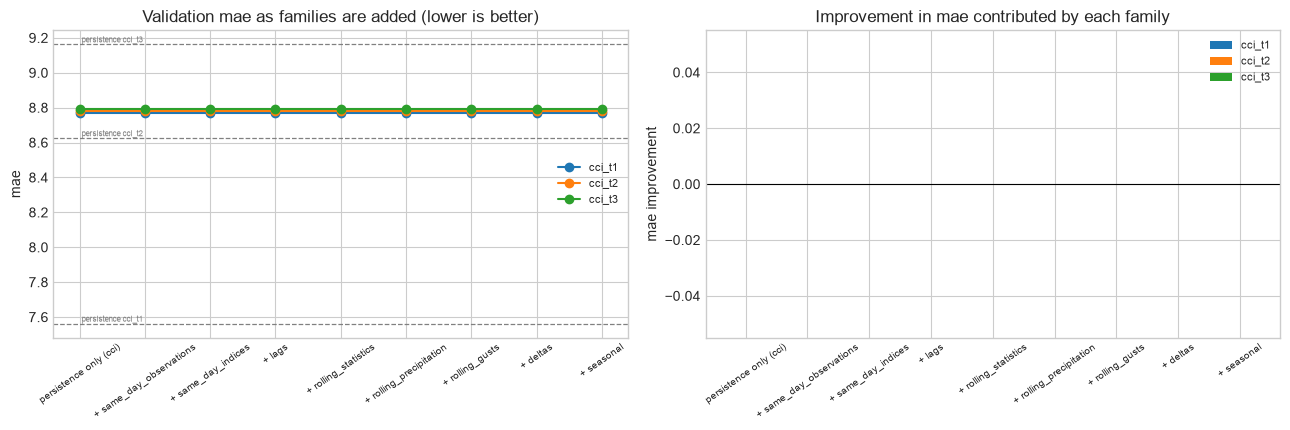

In [6]:
ABLATION_CONFIGS = xp.cumulative_feature_sets(task)


def ablation_score(columns: list[str], target: str) -> dict[str, float]:
    """Fit the default configuration on one feature subset and score it on validation."""
    _, predictions = fit_model(ABLATION_PARAMS, target, columns)
    return xp.regression_metrics(y["val"][target], predictions["val"])


ABLATION = xp.run_ablation(ABLATION_CONFIGS, ablation_score, task.target_columns)
fig, ABLATION_MAE = xp.plot_ablation(
    task, ABLATION, "mae", task.target_columns, f"{EXPERIMENT}-ablation",
    higher_is_better=False,
    reference={f"persistence {t}": v for t, v in BASELINE_MAE.items()},
)
ABLATION_MAE.insert(0, "n_features", [len(c) for c in ABLATION_CONFIGS.values()])
print("Validation MAE by cumulative feature set (lower is better):\n")
print(ABLATION_MAE.to_string())
plt.show()

## 5. Selecting the constant

### Why there is no Optuna in this notebook

The other four CCI notebooks use Optuna because their hyperparameter spaces are continuous,
interacting and far too large to enumerate — a sampler that concentrates on promising regions is
the only practical option. This notebook has no such problem. A `DummyRegressor` is fully
described by a single constant, and the family of candidate constants is one-dimensional.

Running a TPE sampler over a space this small would be worse than pointless. It would sample the
same handful of values repeatedly, report an "importance" for a parameter with two or three
observed levels, and present an exact answer as though it were the outcome of a stochastic
search. Every candidate is evaluated instead, so the selected constant is **optimal by
construction**, not merely the best found within a trial budget.

That distinction matters for how the other notebooks are read. This notebook's number is the true
floor, so any model that fails to beat it has failed against an exactly-known reference rather
than against a lucky draw.

### Which metric is optimised, and why

**Mean absolute error on the validation split, minimised**, per horizon — the identical objective
used by every other CCI notebook, so the floor is measured on the same scale as everything it is
compared against.

MAE is in CCI points, so an improvement reads directly as comfort points. RMSE squares the
residual and is dominated by the rare heavy-rain days where `rain_score` saturates at zero; R² is
a monotone transform of MSE here and carries the same problem.

That choice has a consequence this notebook exists to expose. The minimiser of MAE is the
**median**, not the mean, and the two differ whenever the distribution is skewed. Scanning the
whole quantile family measures the size of that gap directly, which is the quantitative evidence
for whether MAE and RMSE will rank the other models consistently.

### Why validation and not cross-validation

The split is chronological by design. A shuffled k-fold would place future days in the training
folds and inflate every score, because consecutive days are strongly autocorrelated. The fixed
2024 validation period preserves the temporal ordering and matches how the deployed models are
used: fitted on the past, applied forward.

Note the selection bias here is unusually direct — the constant is chosen to minimise error on
the very data used to report it. That optimism is bounded and visible (a one-parameter model can
overfit 363 rows only so far), and the honest estimate still comes from the untouched test split.

In [7]:
CANDIDATES = (
    [{"strategy": "mean"}, {"strategy": "median"}]
    + [{"strategy": "quantile", "quantile": float(q)} for q in QUANTILE_GRID]
)

rows = []
for target in task.target_columns:
    for params in CANDIDATES:
        _, predictions = fit_model(params, target)
        rows.append({
            "target": target,
            "strategy": params["strategy"],
            "quantile": params.get("quantile", np.nan),
            "constant": float(np.asarray(predictions["val"])[0]),
            "val_mae": float(np.mean(np.abs(np.asarray(y["val"][target])
                                            - predictions["val"]))),
        })
SELECTION = pd.DataFrame(rows)

BEST_PARAMS = {}
for target in task.target_columns:
    best = SELECTION[SELECTION["target"] == target].nsmallest(1, "val_mae").iloc[0]
    params = {"strategy": best["strategy"]}
    if best["strategy"] == "quantile":
        params["quantile"] = float(best["quantile"])
    BEST_PARAMS[target] = params
    detail = "" if np.isnan(best["quantile"]) else f", quantile={best['quantile']:.2f}"
    print(f"{target}: best validation MAE {best['val_mae']:.4f} "
          f"from strategy={best['strategy']}{detail} (constant {best['constant']:.3f})")

print("\nMean against median, per horizon:\n")
print(SELECTION[SELECTION["strategy"].isin(["mean", "median"])]
      .pivot(index="target", columns="strategy", values="val_mae")
      .assign(median_advantage=lambda f: f["mean"] - f["median"]).to_string())

cci_t1: best validation MAE 8.6898 from strategy=quantile, quantile=0.35 (constant 68.989)
cci_t2: best validation MAE 8.7032 from strategy=quantile, quantile=0.35 (constant 68.989)
cci_t3: best validation MAE 8.7167 from strategy=quantile, quantile=0.35 (constant 68.987)

Mean against median, per horizon:

strategy  mean  median  median_advantage
target                                  
cci_t1   8.767   8.931            -0.164
cci_t2   8.780   8.945            -0.164
cci_t3   8.793   8.957            -0.164


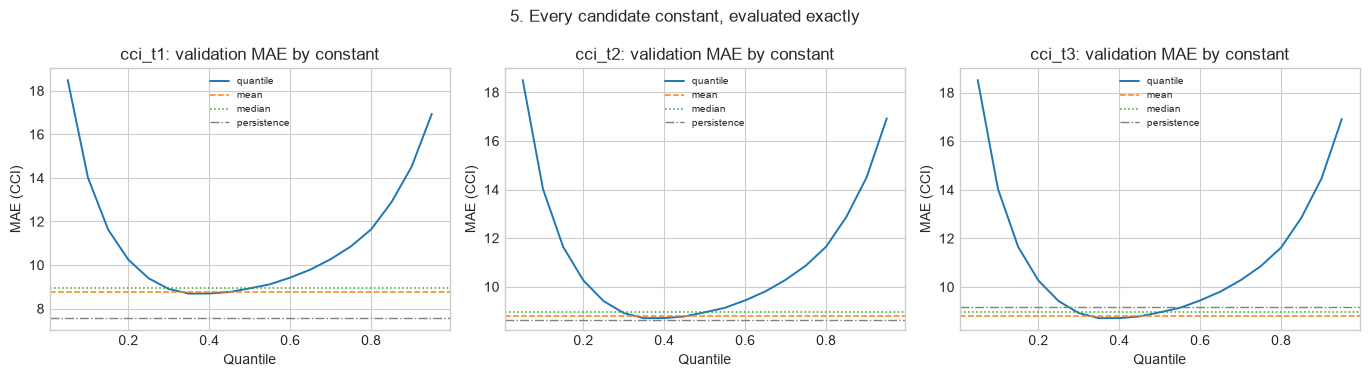

Seed stability (zero spread is expected: a constant predictor has no randomness):

        selected_mae  seed_mean  seed_spread  candidate_spread  deterministic
target                                                                       
cci_t1         8.690      8.690        0.000             9.803           True
cci_t2         8.703      8.703        0.000             9.803           True
cci_t3         8.717      8.717        0.000             9.803           True


In [8]:
fig, axes = plt.subplots(1, len(task.target_columns), figsize=(4.6 * len(task.target_columns), 3.8),
                         squeeze=False)
for column, target in enumerate(task.target_columns):
    axis = axes[0, column]
    grid = SELECTION[(SELECTION["target"] == target) & (SELECTION["strategy"] == "quantile")]
    axis.plot(grid["quantile"], grid["val_mae"], lw=1.4, color="tab:blue", label="quantile")
    for strategy, style, colour in (("mean", "--", "tab:orange"), ("median", ":", "tab:green")):
        value = SELECTION.loc[(SELECTION["target"] == target)
                              & (SELECTION["strategy"] == strategy), "val_mae"].iloc[0]
        axis.axhline(value, ls=style, lw=1.1, color=colour, label=strategy)
    axis.axhline(BASELINE_MAE[target], ls="-.", lw=1.0, color="grey", label="persistence")
    axis.set(title=f"{target}: validation MAE by constant", xlabel="Quantile", ylabel="MAE (CCI)")
    axis.legend(fontsize=7)
fig.suptitle("5. Every candidate constant, evaluated exactly", fontsize=12)
fig.tight_layout()
task.save_figure(fig, f"{EXPERIMENT}-selection")
plt.show()

# The estimator is deterministic, so the seed spread must be exactly zero. That is not a null
# result: it is the reference against which the other notebooks' seed spreads are read. Any
# movement they show is attributable to the algorithm, never to the data or the evaluation code.
stability_rows = []
for target in task.target_columns:
    candidates = SELECTION[SELECTION["target"] == target]["val_mae"]
    seed_values = []
    for seed in SEED_CHECK:
        _, predictions = fit_model(BEST_PARAMS[target], target, seed=seed)
        seed_values.append(float(np.mean(np.abs(
            np.asarray(y["val"][target]) - predictions["val"]))))
    stability_rows.append({
        "target": target,
        "selected_mae": float(candidates.min()),
        "seed_mean": float(np.mean(seed_values)),
        "seed_spread": float(np.max(seed_values) - np.min(seed_values)),
        "candidate_spread": float(candidates.max() - candidates.min()),
        "deterministic": float(np.max(seed_values) - np.min(seed_values)) == 0.0,
    })
STABILITY = pd.DataFrame(stability_rows).set_index("target")
print("Seed stability (zero spread is expected: a constant predictor has no randomness):\n")
print(STABILITY.to_string())

## 6. Final models and evaluation against the baselines

The selected hyperparameters are refitted per horizon and scored against both baselines and
against the default configuration, so the notebook reports what tuning actually bought.

`pred_std` sits alongside the error metrics. It is the direct test for a model that has retreated
to predicting the mean: a spread far below the observed spread means the model is declining to
commit, which can produce a respectable MAE while being useless for identifying the uncomfortable
days a user actually cares about.

Expect error to grow with horizon. Atmospheric predictability decays, and the persistence
correlation measured during preprocessing fell sharply from *t*+1 to *t*+3, so a model that
performs equally well at all three horizons would be more suspicious than impressive.

Validation performance:

                              mae   rmse     r2  pred_std  observed_std
target model                                                           
cci_t1 dummy_mean           8.690 11.019 -0.003     0.000        11.016
       dummy_mean (default) 8.767 11.128 -0.023     0.000        11.016
       persistence          7.562  9.928  0.185    10.937        11.016
       climatology          7.627 10.135  0.151     3.723        11.016
cci_t2 dummy_mean           8.703 11.033 -0.003     0.000        11.029
       dummy_mean (default) 8.780 11.140 -0.023     0.000        11.029
       persistence          8.624 11.521 -0.094    10.937        11.029
       climatology          7.640 10.141  0.152     3.722        11.029
cci_t3 dummy_mean           8.717 11.043 -0.004     0.000        11.038
       dummy_mean (default) 8.793 11.145 -0.022     0.000        11.038
       persistence          9.162 12.015 -0.188    10.937        11.038
       climatology          7.651 10.14

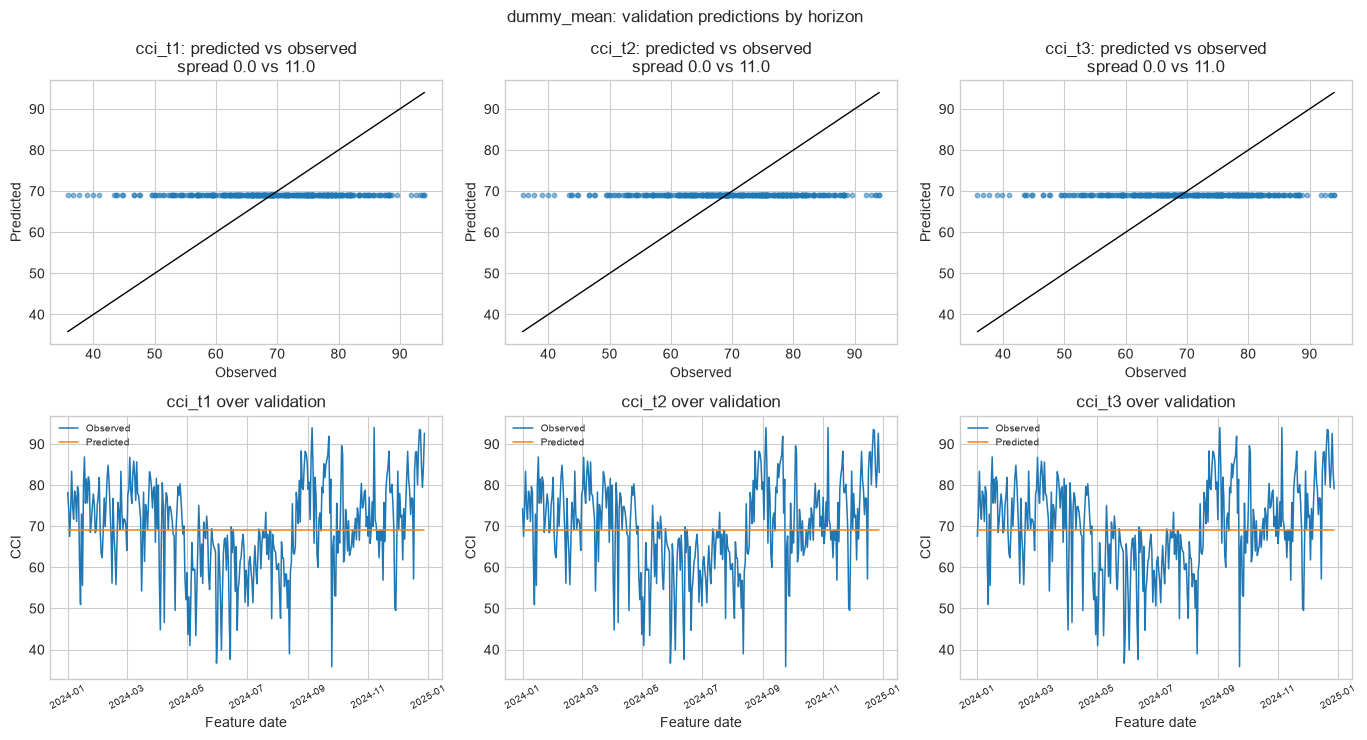

In [9]:
models, VAL_PREDICTIONS, TRAIN_PREDICTIONS = {}, {}, {}
rows = []
for target in task.target_columns:
    model, predictions = fit_model(BEST_PARAMS[target], target)
    models[target] = model
    VAL_PREDICTIONS[target] = predictions["val"]
    TRAIN_PREDICTIONS[target] = predictions["train"]
    rows.append({"target": target, "model": MODEL_LABEL,
                 **xp.regression_metrics(y["val"][target], predictions["val"])})
    rows.append({"target": target, "model": f"{MODEL_LABEL} (default)",
                 **xp.regression_metrics(y["val"][target], default_predictions[target])})
    for label, prediction in BASELINE_PREDICTIONS[target].items():
        rows.append({"target": target, "model": label,
                     **xp.regression_metrics(y["val"][target], prediction)})

RESULTS = pd.DataFrame(rows).set_index(["target", "model"])
RESULTS["observed_std"] = [float(y["val"][t].std()) for t in RESULTS.index.get_level_values(0)]
print("Validation performance:\n")
print(RESULTS.to_string())

comparison = []
for target in task.target_columns:
    tuned = RESULTS.loc[(target, MODEL_LABEL), "mae"]
    for reference in (f"{MODEL_LABEL} (default)", "persistence", "climatology"):
        baseline = RESULTS.loc[(target, reference), "mae"]
        comparison.append({"target": target, "reference": reference,
                           "mae_reduction": baseline - tuned,
                           "relative": (baseline - tuned) / baseline})
COMPARISON = pd.DataFrame(comparison).set_index(["target", "reference"])
print("\nImprovement over each reference (positive means the tuned model is better):\n")
print(COMPARISON.to_string(formatters={"relative": "{:.1%}".format}))

xp.plot_regression_validation(
    task, X["val"].index,
    {t: y["val"][t].to_numpy() for t in task.target_columns},
    VAL_PREDICTIONS, MODEL_LABEL, f"{EXPERIMENT}-validation",
)
plt.show()

## 7. Feature attribution

There is nothing to attribute. This estimator makes no use of the feature matrix, which is the
entire point of a null model: it establishes what can be achieved from the label distribution
alone, so that every other notebook's performance can be read as the value added by the features.

The feature column list is still recorded in the exported bundle, so that the comparison notebook
and the `/model-metadata` endpoint can treat every experiment's artefacts identically.

In [10]:
# A dummy estimator ignores the feature matrix entirely, so there is no importance to report.
# The empty frame keeps the artefact schema identical to the other experiments, which is what
# lets the comparison notebook and the /model-metadata endpoint treat every bundle the same way.
IMPORTANCES = pd.DataFrame()
print("No feature importance: this estimator makes no use of the feature matrix.")
print(f"Feature columns are still recorded ({len(task.feature_columns)}) so that every "
      "experiment\nbundle carries the same contract.")

No feature importance: this estimator makes no use of the feature matrix.
Feature columns are still recorded (105) so that every experiment
bundle carries the same contract.


## 8. Generalisation check

Training and validation error side by side. The ratio is the diagnostic: a value near 1 means the
model generalises, and a large value means it has fitted the training period in ways that do not
transfer to 2024.

Read this together with the seed-stability table in section 5. A model with a wide train-to-
validation gap *and* a large seed spread is not overfitting a fixable configuration — it is
fitting noise, which on this dataset points to weak signal rather than a tuning problem.

In [11]:
gap_rows = []
for target in task.target_columns:
    for split, prediction in (("train", TRAIN_PREDICTIONS[target]),
                              ("val", VAL_PREDICTIONS[target])):
        gap_rows.append({"target": target, "split": split,
                         **xp.regression_metrics(y[split][target], prediction)})

GAP = pd.DataFrame(gap_rows).set_index(["target", "split"])
print(GAP.to_string())

mae_gap = GAP["mae"].unstack()
mae_gap["val_to_train_ratio"] = mae_gap["val"] / mae_gap["train"]
print("\nValidation-to-training MAE ratio (near 1 means the model generalises):")
print(mae_gap.to_string())

               mae   rmse     r2  pred_std
target split                              
cci_t1 train 8.369 10.517 -0.051     0.000
       val   8.690 11.019 -0.003     0.000
cci_t2 train 8.370 10.518 -0.051     0.000
       val   8.703 11.033 -0.003     0.000
cci_t3 train 8.365 10.514 -0.051     0.000
       val   8.717 11.043 -0.004     0.000

Validation-to-training MAE ratio (near 1 means the model generalises):
split   train   val  val_to_train_ratio
target                                 
cci_t1  8.369 8.690               1.038
cci_t2  8.370 8.703               1.040
cci_t3  8.365 8.717               1.042


## 9. Saved artefacts

One model per horizon is written, together with a metadata document shaped for the
`/model-metadata` endpoint: target, algorithm, forecast horizon, feature list, feature importance,
selected hyperparameters and validation metrics.

The metadata records the exact feature column order. The API must construct its feature vector in
that order, since the estimator receives an unnamed array at prediction time and will silently
produce wrong answers if the columns are permuted.

The test split remains unused.

In [12]:
model_entries = []
for target in task.target_columns:
    horizon = int(target.rsplit("t", 1)[-1])
    model_entries.append({
        "target": task.target_name,
        "target_column": target,
        "prediction_type": "regression",
        "algorithm": ALGORITHM_NAME,
        "forecast_horizon": f"{horizon} Day{'s' if horizon > 1 else ''}",
        "hyperparameters": {k: (v if isinstance(v, (int, float, str, bool, type(None)))
                                else str(v)) for k, v in BEST_PARAMS[target].items()},
        "features": task.feature_columns,
        "feature_importance": {
            column: float(value) for column, value
            in IMPORTANCES[target].sort_values(ascending=False).head(20).items()
        } if not IMPORTANCES.empty else {},
        "validation_metrics": RESULTS.loc[(target, MODEL_LABEL)].drop("observed_std").to_dict(),
        "baseline_metrics": {
            reference: RESULTS.loc[(target, reference)].drop("observed_std").to_dict()
            for reference in ("persistence", "climatology")
        },
    })

METADATA = xp.build_metadata(
    task, EXPERIMENT, ALGORITHM_NAME, model_entries,
    best_params={t: {k: str(v) for k, v in p.items()} for t, p in BEST_PARAMS.items()},
    extra={
        "optimisation": {
            "library": None,
            "method": "exhaustive grid over every constant-prediction strategy",
            "objective": "validation mean absolute error",
            "direction": "minimize",
            "candidates_per_horizon": int(len(SELECTION) / len(task.target_columns)),
            "note": (
                "The space is small enough to enumerate, so no search library is used and the "
                "selected constant is exact rather than best-found."
            ),
        },
        "seed_stability": STABILITY.reset_index().to_dict(orient="records"),
    },
)
bundle = xp.export_experiment(task, EXPERIMENT, models, METADATA, MODEL_FAMILY)
print(f"Saved bundle: {bundle.relative_to(PROJECT_ROOT)}")
print("\nThe test split has still not been touched. It should be used exactly once, after a")
print("single model has been selected on validation performance across all experiments.")

Saved bundle: models/comfort_climate/experiments/cci_dummy_mean

The test split has still not been touched. It should be used exactly once, after a
single model has been selected on validation performance across all experiments.


## 10. Conclusions

- **This is the floor, not the bar.** Persistence and climatology both use information and should
  beat it comfortably. Report the size of those gaps: they measure how much the current weather
  and the calendar are each worth before any model is fitted.
- **Mean versus median.** If the tuned quantile sits away from 0.5, CCI's skew is material and
  the gap between MAE and RMSE rankings in the other notebooks has an explanation.
- **`pred_std` is zero by construction.** Every other notebook reports that statistic to detect a
  model retreating toward the mean. This notebook *is* that retreat, so it calibrates how to read
  the number elsewhere.

The test split has still not been touched. It should be used exactly once, after a single model
has been selected on validation performance across all ten experiment notebooks.